# 03 Spectral models on mean spectra: PCA, PLS, an MLP and a 1D ResNet

Rebuilt from the course notebook `2026/end2end_spectral_vs_spatial_models.ipynb` (https://github.com/LizaGenke/Chemometric-approaches-to-hyperspectral-processing,
commit `0d2c33e`). The course takes the mean absorbance spectrum of each pork belly (the
trailing 124 bands, 747.92 to 1015.78 nm), splits the bellies by the table's `split` column (0 is
the test set, 1 the validation set, 2 to 5 the rest of the training set), standardises every
value with one mean and one standard deviation, looks at a three-component PCA, fits PLS with
the component count chosen on the validation split, and trains an MLP and a 1D ResNet from
scratch. The 2D ResNet and the ViT on the slice images are deferred to a later phase.

The course's MLP and 1D ResNet numbers come from the weights the course ships
(`mlp/best_weights.pt`, `resnet1d/best_weights.pt`), loaded into `SpectrumRegressor`; their
training is shown as trainruns at the end.

In [1]:
# Colab bootstrap: installs cuvis-ai when this notebook runs on Colab, a no-op locally. The course
# plugin lives in a private repository until the course authors confirm the licence, so for now the
# notebook runs from a local checkout of this repository (`uv sync --all-extras`).
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q cuvis-ai

In [2]:
# Provision the plugins this notebook needs. Their pins live in the plugin manifests packaged with
# cuvis-ai (cuvis_ai/configs/plugins) and in this repository's own manifest (plugins/): `provision`
# reads them off a pipeline that lists the same plugins, adds each manifest's extras and the data
# module's, and installs only what is missing. After a fresh install, restart the kernel
# (Kernel > Restart Kernel) and rerun from the top. This repository also pins the sam3 and
# ultralytics plugins as its `plugins` extra, so `uv sync --all-extras` has installed them already.
from importlib.resources import files
from pathlib import Path

from cuvis_ai_core.utils.provision import provision_environment, resolve_install_specs

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
CONFIGS = files("cuvis_ai") / "configs"
PLUGINS_DIRS = [REPO / "plugins", Path(str(CONFIGS / "plugins"))]
PROVISION = [  # (pipeline of this repository that lists the plugin(s), data module whose extras to add)
    ("03_spectral_vs_spatial/spectral_models.yaml", 'wur_course_npz'),
]
for pipeline_yaml, data_module in PROVISION:
    pipeline_path = REPO / "pipelines" / pipeline_yaml
    if IN_COLAB:  # no uv project on Colab: pip the resolved specs straight into this kernel
        specs = resolve_install_specs(pipeline_path, PLUGINS_DIRS, data_module)
        provision_environment(specs, notebook=True, apply=True)
    else:  # the same command you would run in a terminal from the repository root
        data_arg = f"--data-module {data_module}" if data_module else ""
        plugin_args = " ".join(f'--plugins-dir "{d}"' for d in PLUGINS_DIRS)
        !uv run --directory "{REPO}" provision --pipeline-path "{pipeline_path}" {plugin_args} {data_arg} --apply

2026-11-04 22:23:08.410 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'cuvis_ai_builtin' tag v0.21.0 → 8c24a350 from https://github.com/cubert-hyperspectral/cuvis-ai.git
2026-11-04 22:23:08.545 | INFO     | cuvis_ai_core.utils.provision:provision_environment:212 - All plugins already provisioned; nothing to install.


In [3]:
import numpy as np
import pandas as pd
import torch
from loguru import logger

logger.remove()
logger.add(sys.stderr, level="INFO")

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DATA = REPO / "data" / "course"
# The stand-in written by tools/make_synthetic_course_data.py has the course's shapes and random
# content; with it the reproduction table reports our numbers without judging them.
SYNTHETIC = (REPO / "data" / "synthetic_course").exists()
sys.path.insert(0, str(REPO / "notebooks"))
import utils  # noqa: E402  (plotting and table helpers only)

print(f"device {DEVICE}, {'synthetic stand-in' if SYNTHETIC else 'course data'} under {DATA}")

device cuda, course data under D:\code-repos\cuvis-ai-wur-course-2026\wt-6957-standardize\data\course


## Data

The course data (the Drive folder of the WUR course) is not a `PublicDatasets` entry: it is shared
for the course, and its licence for a public repository is pending. This notebook therefore deviates
from the standard provisioning block: `prepare-course-data` converts the Drive folder into the npz
frames read here (`README.md` lists the commands), and `tools/make_synthetic_course_data.py` writes a
random stand-in with the course's shapes so every cell runs before the data arrives.

In [4]:
for subset in ('mean_spectra_03',):
    if not (DATA / subset / "universe.csv").exists():
        raise FileNotFoundError(
            f"{DATA / subset} is missing: run prepare-course-data on the course folder, or "
            "`uv run python tools/make_synthetic_course_data.py` for the stand-in"
        )
pd.read_csv(DATA / 'mean_spectra_03' / "universe.csv").head()

,source,index,materialized_path
0,mean_spectra_03,0,frames/00000.npz
1,mean_spectra_03,1,frames/00001.npz
2,mean_spectra_03,2,frames/00002.npz
3,mean_spectra_03,3,frames/00003.npz
4,mean_spectra_03,4,frames/00004.npz


In [5]:
# The plugin manifests: this repository's course plugin, plus the packaged manifests of the plugins
# the pipelines list. The nodes below are constructed by import, so the registry is what a
# pipeline YAML or the restore-pipeline CLI resolves them through.
from cuvis_ai_core.utils.node_registry import NodeRegistry

registry = NodeRegistry()
registry.register_plugin(str(REPO / "plugins" / "cuvis_ai_wur_course.yaml"))

registry.list_plugins()

2026-11-04 22:23:19.400 | INFO     | cuvis_ai_core.utils.node_registry:register_plugins_installed:573 - Loaded preinstalled plugin 'cuvis_ai_wur_course' with 22 nodes


2026-11-04 22:23:19.400 | INFO     | cuvis_ai_core.utils.node_registry:register_plugin:408 - Registered plugin 'cuvis_ai_wur_course' from D:\code-repos\cuvis-ai-wur-course-2026\wt-6957-standardize\plugins\cuvis_ai_wur_course.yaml


['cuvis_ai_wur_course']

## 1. Standardisation, PCA, PLS and the two trained networks in one graph

Every model reads the same frames. The statistical trainer feeds every node the training split,
which here holds splits 1 to 5 with their fold ids, so each node applies the course's split
semantics itself: the scalar standardiser and the PCA leave fold 1 out (`exclude_folds=[1]`) and
fit on splits 2 to 5 like the course, and only report what the course printed (the
standardisation constants and the explained variance). PLS holds out fold 1 the same way (folds
2 to 5 fit, fold 1 selects the component count, 1 to 20, and the model fitted on folds 2 to 5 is
kept). The two networks carry their own standardisation constants and load the course weights;
with the stand-in data the weight files are placeholders.

In [6]:
from cuvis_ai.node.metrics import ExplainedVarianceMetric
from cuvis_ai.node.pretreatments.standardize import Standardize
from cuvis_ai_core.data.splits_io import load_splits
from cuvis_ai_core.pipeline.pipeline import CuvisPipeline
from cuvis_ai_core.training import StatisticalTrainer
from cuvis_ai_wur_course.data.course_npz import CourseNpzDataModule
from cuvis_ai_wur_course.node.fusion import SpatialMean
from cuvis_ai_wur_course.node.metrics import RegressionMetrics
from cuvis_ai_wur_course.node.models import SpectrumRegressor
from cuvis_ai_wur_course.node.pca import DatasetPCA
from cuvis_ai_wur_course.node.regression import PLSRegression
from cuvis_ai_wur_course.node.source import CourseFrame

BANDS, MAX_COMPONENTS = 124, 20

frame = CourseFrame(name="frame")
standardize = Standardize(name="standardize", axis="global", ddof=0, eps=1e-6, exclude_folds=[1])
pca = DatasetPCA(name="pca", input_channels=BANDS, n_components=3, exclude_folds=[1])
explained_variance = ExplainedVarianceMetric(name="explained_variance")
pls = PLSRegression(name="pls", input_channels=BANDS, max_components=MAX_COMPONENTS, holdout_folds=[1], refit_on_holdout=False)
mlp = SpectrumRegressor(name="mlp", arch="mlp", input_channels=BANDS, weights_path=str(DATA / "models" / "mlp" / "best_weights.pt"))
resnet1d = SpectrumRegressor(name="resnet1d", arch="resnet1d", input_channels=BANDS, weights_path=str(DATA / "models" / "resnet1d" / "best_weights.pt"))
mean_pls, mean_mlp, mean_resnet1d = SpatialMean(name="mean_pls"), SpatialMean(name="mean_mlp"), SpatialMean(name="mean_resnet1d")
metrics_pls, metrics_mlp, metrics_resnet1d = RegressionMetrics(name="metrics_pls"), RegressionMetrics(name="metrics_mlp"), RegressionMetrics(name="metrics_resnet1d")

pipeline = CuvisPipeline("spectral_models")
pipeline.connect(
    (frame.outputs.cube, standardize.inputs.cube),
    (frame.outputs.fold, standardize.inputs.fold),
    (frame.outputs.cube, pca.inputs.cube),
    (frame.outputs.fold, pca.inputs.fold),
    (pca.outputs.explained_variance_ratio, explained_variance.inputs.explained_variance_ratio),
    (frame.outputs.target, pls.inputs.target),
    (frame.outputs.fold, pls.inputs.fold),
)
for model, mean, metrics in ((pls, mean_pls, metrics_pls), (mlp, mean_mlp, metrics_mlp), (resnet1d, mean_resnet1d, metrics_resnet1d)):
    pipeline.connect(
        (frame.outputs.cube, model.inputs.cube),
        (model.outputs.prediction, mean.inputs.prediction),
        (mean.outputs.prediction, metrics.inputs.prediction),
        (frame.outputs.target, metrics.inputs.target),
    )
pipeline

spectral_models:
CourseFrame()
Standardize()
DatasetPCA()
ExplainedVarianceMetric()
PLSRegression()
SpatialMean()
RegressionMetrics(
  (rmse_metric): MeanSquaredError()
  (r2_metric): R2Score()
  (mae_metric): MeanAbsoluteError()
)
SpectrumRegressor(
  (backbone): MLP(
    (features): Sequential(
      (0): Linear(in_features=124, out_features=256, bias=True)
      (1): Identity()
      (2): ReLU(inplace=True)
      (3): Linear(in_features=256, out_features=128, bias=True)
      (4): Identity()
      (5): ReLU(inplace=True)
    )
    (head): Linear(in_features=128, out_features=1, bias=True)
  )
)
SpatialMean()
RegressionMetrics(
  (rmse_metric): MeanSquaredError()
  (r2_metric): R2Score()
  (mae_metric): MeanAbsoluteError()
)
SpectrumRegressor(
  (backbone): ResNet(
    (conv1): Conv1d(1, 64, kernel_size=(7,), stride=(2,), padding=(3,))
    (bn1): Identity()
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool1d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn1): Identity()
        (relu): ReLU(inplace=True)
        (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): Identity()
      )
      (1): BasicBlock(
        (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn1): Identity()
        (relu): ReLU(inplace=True)
        (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): Identity()
      )
    )
    (layer2): Sequential(
      (0): BasicBlock(
        (conv1): Conv1d(64, 128, kernel_size=(3,), stride=(2,), padding=(1,))
        (bn1): Identity()
        (relu): ReLU(inplace=True)
        (conv2): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): Identity()
        (downsample): Sequential(
          (0): Conv1d(64, 128, kernel_size=(1,), stride=(2,))
          (1): Identity()
        )
      )
      (1): BasicBlock(
        (conv1): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn1): Identity()
        (relu): ReLU(inplace=True)
        (conv2): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): Identity()
      )
    )
    (layer3): Sequential(
      (0): BasicBlock(
        (conv1): Conv1d(128, 256, kernel_size=(3,), stride=(2,), padding=(1,))
        (bn1): Identity()
        (relu): ReLU(inplace=True)
        (conv2): Conv1d(256, 256, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): Identity()
        (downsample): Sequential(
          (0): Conv1d(128, 256, kernel_size=(1,), stride=(2,))
          (1): Identity()
        )
      )
      (1): BasicBlock(
        (conv1): Conv1d(256, 256, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn1): Identity()
        (relu): ReLU(inplace=True)
        (conv2): Conv1d(256, 256, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): Identity()
      )
    )
    (layer4): Sequential(
      (0): BasicBlock(
        (conv1): Conv1d(256, 512, kernel_size=(3,), stride=(2,), padding=(1,))
        (bn1): Identity()
        (relu): ReLU(inplace=True)
        (conv2): Conv1d(512, 512, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): Identity()
        (downsample): Sequential(
          (0): Conv1d(256, 512, kernel_size=(1,), stride=(2,))
          (1): Identity()
        )
      )
      (1): BasicBlock(
        (conv1): Conv1d(512, 512, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn1): Identity()
        (relu): ReLU(inplace=True)
        (conv2): Conv1d(512, 512, kernel_size=(3,), stride=(1,), padding=(1,))
        (bn2): Identity()
      )
    )
    (avgpool): AdaptiveAvgPool1d(output_size=1)
    (fc): Linear(in_features=512, out_features=1, bias=True)
  )
)
SpatialMean()
RegressionMetrics(
  (rmse_metric): MeanSquaredError()
  (r2_metric): R2Score()
  (mae_metric): MeanAbsoluteError()
)
Use `pipeline.visualize()` for Grap

2026-11-04 22:23:20.951 | INFO     | cuvis_ai_core.training.trainers:fit:707 - Training 3 statistical nodes...


2026-11-04 22:23:20.952 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting standardize


2026-11-04 22:23:21.040 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted standardize


2026-11-04 22:23:21.041 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting pca


2026-11-04 22:23:21.125 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted pca


2026-11-04 22:23:21.125 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting pls


2026-11-04 22:23:21.171 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted pls


standardisation: mean 0.031223, std 0.049720
PCA explained variance ratio: [0.9126, 0.0567, 0.0245]
PLS: 6 components selected on hold-out split 1


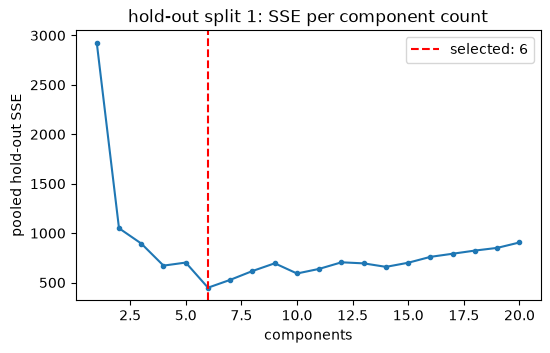

In [7]:
data = CourseNpzDataModule(
    universe_csv=str(DATA / "mean_spectra_03" / "universe.csv"),
    splits=load_splits(DATA / "mean_spectra_03" / "splits.json"),
    batch_size=32,
)
trainer = StatisticalTrainer(pipeline=pipeline, datamodule=data, metric_nodes=[metrics_pls, metrics_mlp, metrics_resnet1d])
trainer.fit()
x_mean, x_std = float(standardize.mean), float(standardize.std)
ratios = [round(float(r), 4) for r in pca._explained_variance_ratio]
print(f"standardisation: mean {x_mean:.6f}, std {x_std:.6f}")
print(f"PCA explained variance ratio: {ratios}")
print(f"PLS: {int(pls.n_selected)} components selected on hold-out split 1")
utils.plot_component_selection(pls.cv_sse, int(pls.n_selected), "hold-out split 1: SSE per component count")

In [8]:
validation = trainer.validate()
val_metrics = {name: node.compute() for name, node in (("pls", metrics_pls), ("mlp", metrics_mlp), ("resnet1d", metrics_resnet1d))}
test = trainer.test()
test_metrics = {name: node.compute() for name, node in (("pls", metrics_pls), ("mlp", metrics_mlp), ("resnet1d", metrics_resnet1d))}
pd.concat({"validation": pd.DataFrame(val_metrics).T, "test": pd.DataFrame(test_metrics).T}, axis=1).round(3)

validation                 test              
               rmse     r2    mae   rmse     r2    mae
pls           4.234  0.896  3.574  5.904  0.799  4.525
mlp           4.999  0.855  4.499  5.544  0.823  4.492
resnet1d      7.334  0.687  5.940  6.226  0.776  5.424

Predict [spectral_models]:   0%|          | 0/2 [00:00<?, ?batch/s]

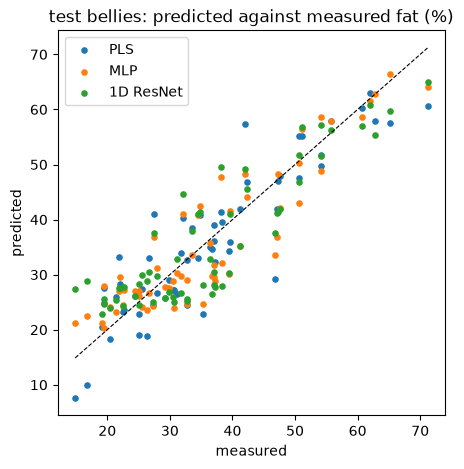

In [9]:
from cuvis_ai_core.training import Predictor
from cuvis_ai_schemas.enums import ExecutionStage
from cuvis_ai_schemas.training.data import DataSplitConfig

test_data = CourseNpzDataModule(
    universe_csv=str(DATA / "mean_spectra_03" / "universe.csv"),
    splits=DataSplitConfig(predict=load_splits(DATA / "mean_spectra_03" / "splits.json").test),
    batch_size=32,
)
outputs = Predictor(pipeline, test_data).predict(stage=ExecutionStage.TEST, collect_outputs=True, collect_ports={"prediction", "target"})
target = torch.cat([o[("frame", "target")] for o in outputs])
predictions = {name: torch.cat([o[(node, "prediction")] for o in outputs]) for name, node in (("PLS", "mean_pls"), ("MLP", "mean_mlp"), ("1D ResNet", "mean_resnet1d"))}
utils.plot_predictions(target, predictions, "test bellies: predicted against measured fat (%)")

## 2. Training the networks: the trainruns

The course trains both networks with AdamW, one full batch per epoch, a plateau scheduler and
early stopping (`train_regressor`). The same recipe is `trainruns/mlp_train.yaml` and
`trainruns/resnet1d_train.yaml`: a trainable copy of the model with the MSE loss in fat percent
and the pooled regression metrics (`pipelines/03_spectral_vs_spatial/*_train.yaml`), the
optimiser, scheduler and callbacks under `training:`. The runs read
`data/course/mean_spectra_03/splits_gradient.json`, which keeps the course's split semantics for
gradient training (splits 2 to 5 train, split 1 validates, split 0 tests); `splits.json` keeps
split 1 inside the training split for the hold-out fits above. Three course details are not in the
trainrun and are listed in its header: the burn-in before early stopping counts, the restore of
the best checkpoint on every learning-rate drop, and the post-hoc bias and scale correction.
With the stand-in data the runs are cut to a few epochs; with the course data they run as written.

In [10]:
print((REPO / "trainruns" / "mlp_train.yaml").read_text(encoding="utf-8"))

# Gradient training of the course's MLP spectrum regressor from random weights (notebook 03).
#
# Run from the repository root:
#   uv run restore-trainrun --trainrun-path trainruns/mlp_train.yaml --plugins-dir plugins --mode train
#
# Course settings kept: AdamW with lr 1e-2 and weight decay 1e-4, MSE in fat percent, one batch
# per epoch (97 training spectra fit in one batch of 128), ReduceLROnPlateau with factor 0.1,
# patience 39 and a floor of 1e-7, early stopping after 200 epochs without improvement, 2000
# epochs at most, seed 42.
# Deviations from the course loop: no 100-epoch burn-in before early stopping counts, no restore
# of the best checkpoint on every learning-rate drop (the checkpoint callback keeps the best epoch
# instead), and no post-hoc bias and scale correction of the predictions.
name: mlp_train
pipeline: ../pipelines/03_spectral_vs_spatial/mlp_train.yaml
output_dir: outputs/mlp_train
data:
  data_module: wur_course_npz
  splits:
    # train = splits 2 to 5 and v

In [11]:
import subprocess

EPOCHS = 20 if SYNTHETIC else None
best_val_mse = {}
for run in ("mlp_train", "resnet1d_train"):
    command = [
        "uv", "run", "restore-trainrun",
        "--trainrun-path", str(REPO / "trainruns" / f"{run}.yaml"),
        *[arg for d in PLUGINS_DIRS for arg in ("--plugins-dir", str(d))],
        "--mode", "train",
        "--override", f"output_dir=outputs/notebook_{run}",
    ]
    if EPOCHS is not None:
        command += ["--override", f"training.max_epochs={EPOCHS}"]
    result = subprocess.run(command, cwd=REPO, capture_output=True, text=True, check=False)
    if result.returncode != 0:
        raise RuntimeError(result.stderr[-4000:])
    restored = CuvisPipeline.load_pipeline(
        str(REPO / "outputs" / f"notebook_{run}" / "trained_models" / f"{run}_restored.yaml"),
        weights_path=str(REPO / "outputs" / f"notebook_{run}" / "trained_models" / f"{run}_restored.pt"),
    )
    restored_metrics = next(node for node in restored.nodes() if node.name == "metrics")
    StatisticalTrainer(pipeline=restored, datamodule=data, metric_nodes=[restored_metrics]).validate()
    best_val_mse[run] = round(restored_metrics.compute()["rmse"] ** 2, 2)
    print(f"{run}: best epoch restored, validation MSE {best_val_mse[run]} (fat percent squared)")

mlp_train: best epoch restored, validation MSE 27.68 (fat percent squared)


resnet1d_train: best epoch restored, validation MSE 58.42 (fat percent squared)


## Reproduction

The course numbers are the printed outputs of the course notebook at the commit named at the top.
The MLP and 1D ResNet test rows come from the course weights. The 1D ResNet RMSE row allows 0.002:
the course code itself gives 6.226 on this machine against the printed 6.227, the last digit
moves with the convolution kernels. The two "own trainrun" rows compare the best validation MSE
of our runs with the course's training runs and are judged within 15 percent; our loop keeps the
course's optimiser, schedule and early stopping but not its burn-in, its restore of the best
weights on every learning-rate drop or its post-hoc bias correction. The MLP run lands inside
that band. The 1D ResNet run does not: at the course's learning rate of 0.01 the course's own run
explodes in its first epoch and recovers only because its loop keeps the best weights across the
rate drops and ignores early stopping for 100 epochs; ours peaks at epoch 53, the plateau
scheduler then decays the rate to its floor and early stopping ends the run, so its row stays an
open deviation. The 2D ResNet (28.770 / 55.271) and ViT (26.488 / 56.763) rows are deferred.

In [12]:
rows = [
    ("standardisation mean", 0.031223, round(x_mean, 6), 1e-3),
    ("standardisation std", 0.049720, round(x_std, 6), 1e-3),
    ("PCA explained variance, component 1", 0.9126, ratios[0], 1e-3),
    ("PCA explained variance, component 2", 0.0567, ratios[1], 1e-3),
    ("PCA explained variance, component 3", 0.0245, ratios[2], 1e-3),
    ("PLS components", 6, int(pls.n_selected), 0),
    ("PLS validation RMSE", 4.234, round(val_metrics["pls"]["rmse"], 3), 1e-3),
    ("PLS test RMSE", 5.904, round(test_metrics["pls"]["rmse"], 3), 1e-3),
    ("PLS test R2", 0.799, round(test_metrics["pls"]["r2"], 3), 1e-3),
    ("MLP test RMSE", 5.544, round(test_metrics["mlp"]["rmse"], 3), 1e-3),
    ("MLP test R2", 0.823, round(test_metrics["mlp"]["r2"], 3), 1e-3),
    ("1D ResNet test RMSE", 6.227, round(test_metrics["resnet1d"]["rmse"], 3), 2e-3),
    ("1D ResNet test R2", 0.776, round(test_metrics["resnet1d"]["r2"], 3), 1e-3),
    ("own MLP trainrun, best validation MSE", 29.04, best_val_mse["mlp_train"], 0.15 * 29.04),
    ("own 1D ResNet trainrun, best validation MSE", 34.30, best_val_mse["resnet1d_train"], 0.15 * 34.30),
]
utils.reproduction_table(rows, synthetic=SYNTHETIC)

,row,course,ours,tolerance,status
0,standardisation mean,0.031223,0.031223,0.001,pass
1,standardisation std,0.049720,0.049720,0.001,pass
2,"PCA explained variance, component 1",0.912600,0.912600,0.001,pass
3,"PCA explained variance, component 2",0.056700,0.056700,0.001,pass
4,"PCA explained variance, component 3",0.024500,0.024500,0.001,pass
5,PLS components,6.000000,6.000000,0.000,pass
6,PLS validation RMSE,4.234000,4.234000,0.001,pass
7,PLS test RMSE,5.904000,5.904000,0.001,pass
8,PLS test R2,0.799000,0.799000,0.001,pass
9,MLP test RMSE,5.544000,5.544000,0.001,pass
